<a href="https://colab.research.google.com/github/miriamamin1213-ux/AUC_Curves/blob/main/HecktorGPT2Unfrozen2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# HECKTOR GPT-2 Last 2 Blocks Unfrozen
# HPV Status Prediction | Compact Single-Cell Notebook
# ============================================================

# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
import os, random, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

SEED = 42
def seed_everything(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. LOAD HECKTOR EXCEL DATA
DATA_FILE = "HPV2025.xlsx"
if not os.path.exists(DATA_FILE):
    downloaded = gdown.download(
        id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
        output=DATA_FILE, quiet=False
    )
    if downloaded is None or not os.path.exists(DATA_FILE):
        raise FileNotFoundError("Could not download HPV2025.xlsx.")

df = pd.read_excel(DATA_FILE)
TARGET = "HPV Status"
FEATURES = [
    "Age", "Gender", "Tobacco Consumption", "Alcohol Consumption",
    "Performance Status", "T-stage", "N-stage", "M-stage"
]
missing = [c for c in [TARGET] + FEATURES if c not in df.columns]
if missing:
    raise KeyError(f"Required Excel columns missing: {missing}")

# 3. ROBUSTLY NORMALISE TARGET AND SELECT FEATURES
def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in {"0", "0.0", "negative", "neg", "false", "no"}:
        return 0
    if s in {"1", "1.0", "positive", "pos", "true", "yes"}:
        return 1
    try:
        n = float(s)
        if n in (0, 1):
            return int(n)
    except (ValueError, TypeError):
        pass
    return np.nan

df["HPV_Label"] = df[TARGET].apply(normalize_target)
invalid_count = int(df["HPV_Label"].isna().sum())
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[FEATURES + ["HPV_Label"]].copy()

if df.empty:
    raise ValueError("No recognised HPV labels found; check the target column.")
counts = df["HPV_Label"].value_counts().reindex([0, 1], fill_value=0)
if (counts < 2).any():
    raise ValueError(f"Insufficient examples for both HPV classes: {counts.to_dict()}")

print("Dataset:", df.shape, "| Invalid/missing target rows dropped:", invalid_count)
print("HPV classes (0=negative, 1=positive):\n", counts)

# 4. STRATIFIED TRAIN / VALIDATION / TEST SPLIT (65/15/20)
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = [x.copy() for x in (train_df, val_df, test_df)]

# 5. IMPUTE MISSING FEATURES USING TRAINING DATA ONLY
fill_values = {}
for col in FEATURES:
    if pd.api.types.is_numeric_dtype(train_df[col]):
        value = train_df[col].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[col].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[col] = value
    for split in (train_df, val_df, test_df):
        split[col] = split[col].fillna(value)
        if split[col].dtype == object:
            split[col] = split[col].astype(str).replace(
                {"": "Unknown", "nan": "Unknown", "None": "Unknown"}
            )

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
for name, y in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name}: n={len(y)}, class counts={np.bincount(y, minlength=2)}")

# 6. CONVERT CLINICAL FEATURES INTO TEXT PROMPTS
def display_value(x):
    if pd.isna(x):
        return "Unknown"
    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))
    return str(x).strip()

def format_stage(x, prefix):
    value = display_value(x)
    if value == "Unknown" or value.upper().startswith(prefix):
        return value
    try:
        n = float(value)
        if n.is_integer():
            return f"{prefix}{int(n)}"
    except ValueError:
        pass
    return f"{prefix}{value}"

def patient_to_text(row):
    labels = {
        "Age": "Age", "Gender": "Gender",
        "Tobacco Consumption": "Tobacco consumption",
        "Alcohol Consumption": "Alcohol consumption",
        "Performance Status": "Performance status",
        "T-stage": "Tumour T stage", "N-stage": "Nodal N stage",
        "M-stage": "Metastatic M stage"
    }
    parts = ["Q: Predict this patient's HPV status from the following HECKTOR clinical information."]
    for col in FEATURES:
        value = display_value(row[col])
        if col in ("T-stage", "N-stage", "M-stage"):
            value = format_stage(row[col], col[0])
        parts.append(f"{labels[col]}: {value}.")
    parts.append("Is this patient HPV positive? Answer Yes or No.\nA:")
    return " ".join(parts)

train_texts = [patient_to_text(r) for _, r in train_df.iterrows()]
val_texts = [patient_to_text(r) for _, r in val_df.iterrows()]
test_texts = [patient_to_text(r) for _, r in test_df.iterrows()]

# 7. LOAD TOKENIZER AND SET TRAINING PARAMETERS
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token
lengths = [len(tokenizer.encode(t, add_special_tokens=False)) for t in train_texts]
MAX_LENGTH = min(1024, max(32, int(np.ceil(max(lengths) / 8) * 8)))
BATCH_SIZE, EPOCHS = 64, 500
LEARNING_RATE, WEIGHT_DECAY, DROPOUT = 1e-3, 1e-4, 0.1
print("Max prompt length:", max(lengths), "| MAX_LENGTH:", MAX_LENGTH)
print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS)

# 8. BUILD DATASETS AND DATA LOADERS
class HPVTextDataset(Dataset):
    def __init__(self, texts, labels):
        self.items = []
        for text, label in zip(texts, labels):
            enc = tokenizer(
                text, max_length=MAX_LENGTH, padding="max_length",
                truncation=True, return_tensors="pt"
            )
            self.items.append((
                enc["input_ids"].squeeze(0),
                enc["attention_mask"].squeeze(0), int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        ids, mask, label = self.items[i]
        return {"input_ids": ids, "attention_mask": mask,
                "label": torch.tensor(label, dtype=torch.long)}

train_ds = HPVTextDataset(train_texts, y_train)
val_ds = HPVTextDataset(val_texts, y_val)
test_ds = HPVTextDataset(test_texts, y_test)
loader_args = {
    "batch_size": BATCH_SIZE, "num_workers": 0,
    "pin_memory": torch.cuda.is_available()
}
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, shuffle=True, generator=generator, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS-WEIGHTED LOSS
class HPVNetGPT2Text(nn.Module):
    def __init__(self):
        super().__init__()
        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)
        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id
        h = self.gpt2.config.hidden_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(h), nn.Dropout(DROPOUT), nn.Linear(h, 128),
            nn.GELU(), nn.Dropout(DROPOUT), nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask):
        out = self.gpt2(
            input_ids=input_ids, attention_mask=attention_mask,
            use_cache=False, return_dict=True
        ).last_hidden_state
        positions = attention_mask.sum(dim=1) - 1
        pooled = out[torch.arange(out.size(0), device=out.device), positions]
        return self.classifier(pooled)


model = HPVNetGPT2Text().to(device)

# Freeze all GPT-2 parameters
for param in model.gpt2.parameters():
    param.requires_grad = False

# Unfreeze the final 2 GPT-2 blocks
for block in model.gpt2.h[-2:]:
    for param in block.parameters():
        param.requires_grad = True

# Keep the classifier head trainable
for param in model.classifier.parameters():
    param.requires_grad = True

# Calculate class weights
class_counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32,
    device=device
)

def weighted_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()

# Optimise only trainable parameters
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Verify trainable parameters
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
total_params = sum(p.numel() for p in model.parameters())

print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")
print("Trainable GPT-2 blocks: final 2; classifier head: trainable")


# 10. VALIDATION SCORING AND THRESHOLD SELECTION
def get_scores(loader):
    model.eval()
    scores, labels = [], []
    with torch.no_grad():
        for batch in loader:
            ids, mask = batch["input_ids"].to(device), batch["attention_mask"].to(device)
            logits = model(ids, mask)
            scores.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            labels.extend(batch["label"].numpy())
    return np.asarray(scores), np.asarray(labels, dtype=int)

def evaluate_loss(loader):
    model.eval()
    total, n_total = 0.0, 0
    with torch.no_grad():
        for b in loader:
            ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
            labels = b["label"].to(device)
            loss = weighted_loss(model(ids, mask), labels)
            n = len(labels); total += loss.item() * n; n_total += n
    return total / max(n_total, 1)

def choose_threshold(scores, labels):
    thresholds = np.unique(np.r_[0.0, scores, 1.0])
    values = [(float(t), balanced_accuracy_score(labels, scores >= t)) for t in thresholds]
    return max(values, key=lambda x: (x[1], -abs(x[0] - 0.5)))

# 11. TRAIN MODEL AND SAVE BEST VALIDATION CHECKPOINTS
OUT_DIR = Path("ROC_HECKTOR_GPT2_CLASSIFIER")
OUT_DIR.mkdir(parents=True, exist_ok=True)
paths = {
    "Validation_Loss": OUT_DIR / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": OUT_DIR / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": OUT_DIR / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy": OUT_DIR / "best_model_validation_balanced_accuracy.pth"
}
best = {
    "Validation_Loss": float("inf"), "Validation_ROC_AUC": -float("inf"),
    "Validation_PR_AUC": -float("inf"), "Validation_Balanced_Accuracy": -float("inf")
}
best_info, history = {}, []

for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum, n_sum = 0.0, 0
    for b in train_loader:
        ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
        labels = b["label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = weighted_loss(model(ids, mask), labels)
        loss.backward()
        optimizer.step()
        n = len(labels); loss_sum += loss.item() * n; n_sum += n

    train_loss = loss_sum / max(n_sum, 1)
    val_loss = evaluate_loss(val_loader)
    val_scores, val_labels = get_scores(val_loader)
    val_auc = roc_auc_score(val_labels, val_scores)
    val_ap = average_precision_score(val_labels, val_scores)
    threshold, val_ba = choose_threshold(val_scores, val_labels)
    metrics = {
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap, "Validation_Balanced_Accuracy": val_ba
    }
    history.append({
        "Epoch": epoch, "Train_Loss": train_loss, **metrics,
        "Validation_Threshold": threshold
    })

    for name, value in metrics.items():
        improved = value < best[name] if name == "Validation_Loss" else value > best[name]
        if improved:
            best[name] = float(value)
            best_info[name] = {"epoch": epoch, "value": float(value), "threshold": threshold}
            torch.save(model.state_dict(), paths[name])

    if epoch % 50 == 0:
        print(f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
              f"Val Loss={val_loss:.4f} | ROC-AUC={val_auc:.4f} | "
              f"PR-AUC={val_ap:.4f} | BA={val_ba:.4f} | Threshold={threshold:.4f}")

pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)
pd.DataFrame([
    {"Checkpoint": k, **v, "Path": str(paths[k])} for k, v in best_info.items()
]).to_csv(OUT_DIR / "best_validation_checkpoints.csv", index=False)

# 12. EVALUATE ALL CHECKPOINTS ON HELD-OUT TEST SET
results, predictions_by_model = [], {}
for name, path in paths.items():
    model.load_state_dict(torch.load(path, map_location=device))
    scores, labels = get_scores(test_loader)
    threshold = best_info[name]["threshold"]
    preds = (scores >= threshold).astype(int)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)
    ba = balanced_accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, zero_division=0)
    cm = confusion_matrix(labels, preds, labels=[0, 1])

    print(f"\n=== {name} | Best epoch {best_info[name]['epoch']} | Threshold {threshold:.4f} ===")
    print(classification_report(
        labels, preds, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"], digits=4, zero_division=0
    ))
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    print(f"Test ROC-AUC={auc:.4f} | PR-AUC={ap:.4f} | BA={ba:.4f} | F1={f1:.4f}")

    results.append({
        "Dataset": "HECKTOR", "Model": "GPT-2 Classifier",
        "Checkpoint_Selected_By": name, "Best_Epoch": best_info[name]["epoch"],
        "Validation_Threshold": threshold, "Test_ROC_AUC": auc,
        "Test_PR_AUC": ap, "Test_Balanced_Accuracy": ba, "Test_F1": f1,
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]
    })
    predictions_by_model[name] = (labels, scores, preds, threshold)
    pd.DataFrame({
        "True_Label": labels, "HPV_Positive_Score": scores,
        "Predicted_Label": preds, "Threshold": threshold
    }).to_csv(OUT_DIR / f"test_predictions_{name.lower()}.csv", index=False)

results_df = pd.DataFrame(results)
results_df.to_csv(OUT_DIR / "test_metrics_by_checkpoint.csv", index=False)

# 13. SAVE ROC AND PRECISION-RECALL CURVES
for name, (labels, scores, preds, threshold) in predictions_by_model.items():
    safe = name.lower()
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, _ = precision_recall_curve(labels, scores)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)

    pd.DataFrame({"FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds}).to_csv(
        OUT_DIR / f"roc_coordinates_{safe}.csv", index=False
    )
    pd.DataFrame({"Precision": precision, "Recall": recall}).to_csv(
        OUT_DIR / f"pr_coordinates_{safe}.csv", index=False
    )

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"HECKTOR ROC — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"roc_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, label=f"AP={ap:.3f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"HECKTOR Precision-Recall — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"pr_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

# 14. SAVE SETTINGS AND COMPARISON RESULTS
settings = {
    "Dataset": "HECKTOR", "Model": MODEL_NAME, "Target": "HPV Status",
    "Features": ", ".join(FEATURES), "Number_of_Features": len(FEATURES),
    "Split": "65/15/20 stratified", "Seed": SEED, "Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE, "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY, "Dropout": DROPOUT,
    "Max_Length": MAX_LENGTH, "Optimizer": "AdamW",
    "Class_Weighted_Loss": True,
    "Class_Weighted_Loss": True,
    "GPT2_Backbone_Frozen": "Partially frozen; final 2 blocks trainable",
    "GPT2_Trainable_Blocks": 2,
    "Checkpoint_Selection": "Validation loss, ROC-AUC, PR-AUC, balanced accuracy",
    "Threshold_Selection": "Maximum validation balanced accuracy"
}
pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)

comparison_file = Path("model_roc_pr_auc_comparison.csv")
comparison = results_df[[
    "Dataset", "Model", "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC", "Test_Balanced_Accuracy", "Test_F1"
]]
if comparison_file.exists():
    old = pd.read_csv(comparison_file)
    combined = pd.concat([old, comparison], ignore_index=True, sort=False)
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"], keep="last"
    )
else:
    combined = comparison
combined.to_csv(comparison_file, index=False)

print("\nAll outputs saved to:", OUT_DIR.resolve())
print("Comparison CSV:", comparison_file.resolve())

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 26.7MB/s]


Dataset: (588, 9) | Invalid/missing target rows dropped: 138
HPV classes (0=negative, 1=positive):
 HPV_Label
0     58
1    530
Name: count, dtype: int64
Train: n=381, class counts=[ 37 344]
Validation: n=89, class counts=[ 9 80]
Test: n=118, class counts=[ 12 106]


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (5 outputs left out)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Trainable parameters: 14,275,970 / 124,540,034
Trainable GPT-2 blocks: final 2; classifier head: trainable


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 50/500 | Train Loss=0.5822 | Val Loss=0.5987 | ROC-AUC=0.7958 | PR-AUC=0.9754 | BA=0.8187 | Threshold=0.4074
Epoch 100/500 | Train Loss=0.5129 | Val Loss=0.5876 | ROC-AUC=0.7681 | PR-AUC=0.9662 | BA=0.7639 | Threshold=0.4073
Epoch 150/500 | Train Loss=0.5519 | Val Loss=0.7748 | ROC-AUC=0.6806 | PR-AUC=0.9519 | BA=0.6951 | Threshold=0.4924
Epoch 200/500 | Train Loss=0.5242 | Val Loss=0.8270 | ROC-AUC=0.6847 | PR-AUC=0.9546 | BA=0.7319 | Threshold=0.5555
Epoch 250/500 | Train Loss=0.5666 | Val Loss=0.7583 | ROC-AUC=0.6681 | PR-AUC=0.9438 | BA=0.7132 | Threshold=0.5062
Epoch 300/500 | Train Loss=0.6064 | Val Loss=0.7145 | ROC-AUC=0.6542 | PR-AUC=0.9353 | BA=0.6757 | Threshold=0.6471
Epoch 350/500 | Train Loss=0.5267 | Val Loss=0.9532 | ROC-AUC=0.6847 | PR-AUC=0.9409 | BA=0.7507 | Threshold=0.4476
Epoch 400/500 | Train Loss=0.5142 | Val Loss=0.8223 | ROC-AUC=0.6889 | PR-AUC=0.9555 | BA=0.7382 | Threshold=0.5552
Epoch 450/500 | Train Loss=0.5087 | Val Loss=0.9831 | ROC-AUC=0.6667 | PR

In [2]:

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix
)

# --------------------------------------------------
# Load Epoch 17 predictions
# --------------------------------------------------
OUT_DIR = Path("/content/ROC_HECKTOR_GPT2_CLASSIFIER")

pred_file = OUT_DIR / "test_predictions_validation_balanced_accuracy.csv"
df = pd.read_csv(pred_file)

y_true = df["True_Label"].to_numpy(dtype=int)
y_score = df["HPV_Positive_Score"].to_numpy(dtype=float)
y_pred = df["Predicted_Label"].to_numpy(dtype=int)
threshold = float(df["Threshold"].iloc[0])

print("Test patients:", len(y_true))
print("Class counts:", np.bincount(y_true, minlength=2))
print("Threshold:", threshold)

# --------------------------------------------------
# Original test metrics
# --------------------------------------------------
tn, fp, fn, tp = confusion_matrix(
    y_true, y_pred, labels=[0, 1]
).ravel()

metrics = {
    "ROC-AUC": roc_auc_score(y_true, y_score),
    "PR-AUC": average_precision_score(y_true, y_score),
    "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
    "Sensitivity": tp / (tp + fn),
    "Specificity": tn / (tn + fp)
}

# --------------------------------------------------
# Stratified bootstrap confidence intervals
# --------------------------------------------------
N_BOOTSTRAP = 5000
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

negative_idx = np.where(y_true == 0)[0]
positive_idx = np.where(y_true == 1)[0]

bootstrap_results = {
    name: [] for name in [
        "ROC-AUC", "PR-AUC", "Balanced Accuracy"
    ]
}

for _ in range(N_BOOTSTRAP):

    # Resample each class separately
    sampled_neg = rng.choice(
        negative_idx, size=len(negative_idx), replace=True
    )
    sampled_pos = rng.choice(
        positive_idx, size=len(positive_idx), replace=True
    )

    sampled_idx = np.concatenate([sampled_neg, sampled_pos])

    yt = y_true[sampled_idx]
    ys = y_score[sampled_idx]
    yp = y_pred[sampled_idx]

    bootstrap_results["ROC-AUC"].append(
        roc_auc_score(yt, ys)
    )
    bootstrap_results["PR-AUC"].append(
        average_precision_score(yt, ys)
    )
    bootstrap_results["Balanced Accuracy"].append(
        balanced_accuracy_score(yt, yp)
    )

# --------------------------------------------------
# Wilson confidence interval for sensitivity/specificity
# --------------------------------------------------
def wilson_ci(successes, total, z=1.959963984540054):
    if total == 0:
        return np.nan, np.nan

    p = successes / total
    denominator = 1 + z**2 / total
    centre = (p + z**2 / (2 * total)) / denominator
    margin = (
        z * np.sqrt(
            p * (1 - p) / total + z**2 / (4 * total**2)
        ) / denominator
    )
    return centre - margin, centre + margin

# --------------------------------------------------
# Compile results
# --------------------------------------------------
rows = []

for metric, value in metrics.items():

    if metric in bootstrap_results:
        lower, upper = np.percentile(
            bootstrap_results[metric], [2.5, 97.5]
        )
        ci_method = "Stratified percentile bootstrap"

    elif metric == "Sensitivity":
        lower, upper = wilson_ci(tp, tp + fn)
        ci_method = "Wilson"

    else:
        lower, upper = wilson_ci(tn, tn + fp)
        ci_method = "Wilson"

    rows.append({
        "Metric": metric,
        "Estimate": value,
        "95% CI Lower": lower,
        "95% CI Upper": upper,
        "CI Method": ci_method
    })

ci_df = pd.DataFrame(rows)

print("\nGPT-2 Last 2 Blocks Unfrozen — 95% Confidence Intervals")
print(ci_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

save_file = OUT_DIR / "GPT2_Last2Blocks_Epoch17_confidence_intervals.csv"
ci_df.to_csv(save_file, index=False)

print("\nSaved to:", save_file)


Test patients: 118
Class counts: [ 12 106]
Threshold: 0.468956857919693

GPT-2 Last 2 Blocks Unfrozen — 95% Confidence Intervals
           Metric  Estimate  95% CI Lower  95% CI Upper                       CI Method
          ROC-AUC    0.8396        0.7508        0.9167 Stratified percentile bootstrap
           PR-AUC    0.9806        0.9690        0.9904 Stratified percentile bootstrap
Balanced Accuracy    0.7980        0.6918        0.8726 Stratified percentile bootstrap
      Sensitivity    0.6792        0.5855        0.7605                          Wilson
      Specificity    0.9167        0.6461        0.9851                          Wilson

Saved to: /content/ROC_HECKTOR_GPT2_CLASSIFIER/GPT2_Last2Blocks_Epoch17_confidence_intervals.csv


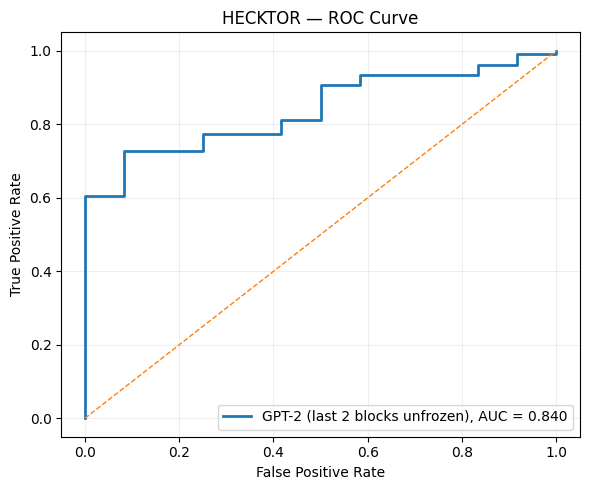

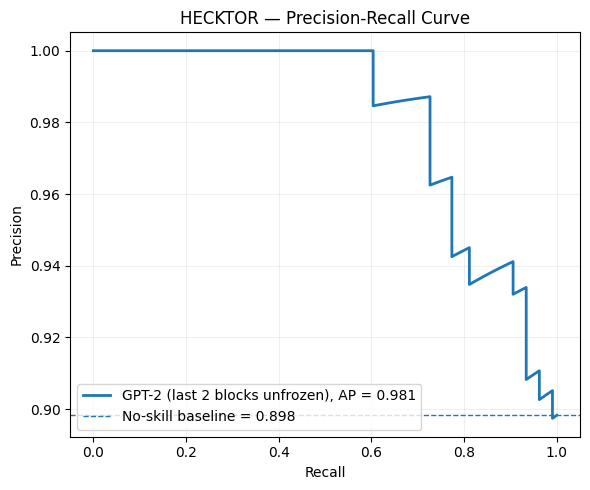

ROC curve saved: /content/ROC_HECKTOR_GPT2_CLASSIFIER/GPT2_Last2Blocks_Epoch17_ROC.png
PR curve saved: /content/ROC_HECKTOR_GPT2_CLASSIFIER/GPT2_Last2Blocks_Epoch17_PR.png


In [3]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# Load Epoch 17 predictions
df = pd.read_csv(
    OUT_DIR / "test_predictions_validation_balanced_accuracy.csv"
)

y_true = df["True_Label"].to_numpy(dtype=int)
y_score = df["HPV_Positive_Score"].to_numpy(dtype=float)

roc_auc = roc_auc_score(y_true, y_score)
pr_auc = average_precision_score(y_true, y_score)

# --------------------------------------------------
# ROC curve
# --------------------------------------------------
fpr, tpr, _ = roc_curve(y_true, y_score)

plt.figure(figsize=(6, 5))
plt.plot(
    fpr, tpr, linewidth=2,
    label=f"GPT-2 (last 2 blocks unfrozen), AUC = {roc_auc:.3f}"
)
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("HECKTOR — ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()

roc_file = OUT_DIR / "GPT2_Last2Blocks_Epoch17_ROC.png"
plt.savefig(roc_file, dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# Precision-recall curve
# --------------------------------------------------
precision, recall, _ = precision_recall_curve(
    y_true, y_score
)

plt.figure(figsize=(6, 5))
plt.plot(
    recall, precision, linewidth=2,
    label=f"GPT-2 (last 2 blocks unfrozen), AP = {pr_auc:.3f}"
)
plt.axhline(
    y_true.mean(), linestyle="--", linewidth=1,
    label=f"No-skill baseline = {y_true.mean():.3f}"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("HECKTOR — Precision-Recall Curve")
plt.legend(loc="lower left")
plt.grid(alpha=0.2)
plt.tight_layout()

pr_file = OUT_DIR / "GPT2_Last2Blocks_Epoch17_PR.png"
plt.savefig(pr_file, dpi=300, bbox_inches="tight")
plt.show()

print("ROC curve saved:", roc_file)
print("PR curve saved:", pr_file)
